# Séance 9 — Long/Short, neutralité de marché et pair trading
**« Gagner dans toutes les directions »**

Plan : (1) univers & IC cross-sectionnel · (2) portefeuille long/short vs long-only · (3) expositions ·
(4) beta glissant & couverture · (5) coût d'emprunt · (6) corrélation vs cointégration · (7) pair trading · (8) stabilité & limites.

> ⚠ Si le téléchargement échoue, le notebook bascule sur des **données simulées** (`SYNTHETIC = True`).
> Les résultats n'ont alors aucune valeur économique.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from backtester.engine import PortfolioBacktester
from backtester.factors import (momentum_factor, volatility_factor, cross_sectional_ic,
                                cross_sectional_icir, ic_summary, fama_french_alpha)
from backtester.metrics import full_metrics
from backtester.pairs import (cointegration_test, pairs_signal, pair_returns, spread, spread_zscore,
                              hedge_ratio, half_life)
from backtester.portfolio import (quantile_weights, rolling_beta, portfolio_beta, beta_hedge,
                                  hedged_returns, portfolio_returns, exposure_summary)

# ── Palette (thème sombre, cohérent avec les séances précédentes)
BG, FG, GRID = "#0f1419", "#e6e6e6", "#2a313a"
BLUE, GREEN, RED, ORANGE, PURPLE, GREY = "#4cc9f0", "#80ed99", "#ff6b6b", "#ffb703", "#b388eb", "#8d99ae"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": FG, "text.color": FG,
    "xtick.color": FG, "ytick.color": FG, "grid.color": GRID, "grid.alpha": 0.6,
    "axes.grid": True, "legend.facecolor": BG, "legend.edgecolor": GRID,
    "figure.figsize": (11, 4.5), "axes.titleweight": "bold",
})
REPORTS = Path.cwd().parent / "reports"; REPORTS.mkdir(exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(REPORTS / f"s9_{name}.png", dpi=130)

## 1. Univers et IC cross-sectionnel

In [2]:
TICKERS = ["AAPL","MSFT","GOOGL","AMZN","META","NVDA","JPM","BAC","XOM","CVX",
           "KO","PEP","WMT","PG","JNJ","PFE","V","MA","HD","DIS"]
START, END = "2015-01-01", "2025-12-31"
BORROW_BPS = 30   # large caps liquides : 10-50 bps/an ; small caps : bien plus

SYNTHETIC = False
try:
    import yfinance as yf
    raw = yf.download(TICKERS + ["SPY"], start=START, end=END, auto_adjust=True, progress=False)["Close"].dropna(how="all")
    assert not raw.empty
    close = raw[TICKERS].dropna(axis=1, thresh=int(len(raw) * 0.9)); spy = raw["SPY"]
except Exception as e:
    print("Téléchargement impossible → données simulées :", type(e).__name__)
    from backtester.synthetic import make_universe
    close, spy = make_universe(); SYNTHETIC = True

rets, spy_r = close.pct_change(), spy.pct_change()
fwd = rets.shift(-1)      # seul shift(-1) autorisé : MESURER l'IC a posteriori
print(f"{close.shape[1]} actifs · {len(close)} jours · {close.index[0].date()} → {close.index[-1].date()} · SYNTHETIC={SYNTHETIC}")

20 actifs · 2765 jours · 2015-01-02 → 2025-12-30 · SYNTHETIC=False


**Biais de survie** : un univers de tickers *actuels* exclut les entreprises tombées ; les jambes longues sont
mécaniquement avantagées. Le Sharpe réel d'une telle stratégie est donc probablement **surestimé**.

,momentum 12-1,low-vol
IC moyen,0.0252,-0.0189
IC std,0.3786,0.3827
ICIR,0.0670,-0.0490
ICIR annualisé,1.0600,-0.7800
t-stat,3.3400,-2.5600
IC > 0 (%),53.6000,47.6000
nb dates,2512.0000,2701.0000


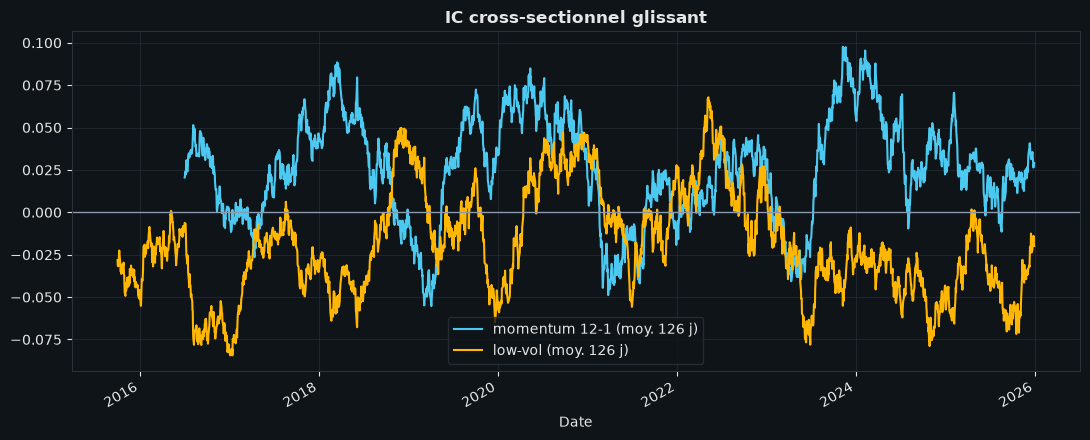

In [3]:
factors = {"momentum 12-1": momentum_factor(close), "low-vol": volatility_factor(close)}
ics = {k: cross_sectional_ic(v, fwd) for k, v in factors.items()}
display(pd.DataFrame({k: ic_summary(v) for k, v in ics.items()}))

fig, ax = plt.subplots()
for (k, ic), c in zip(ics.items(), [BLUE, ORANGE]):
    ic.rolling(126).mean().plot(ax=ax, color=c, label=f"{k} (moy. 126 j)")
ax.axhline(0, color=GREY, lw=1); ax.set_title("IC cross-sectionnel glissant"); ax.legend(); save("ic")
plt.show()

## 2. Long/short vs long-only (momentum, 20 % / 20 %, rebalancement mensuel)

,L/S net,L/S brut,Long-only
CAGR (%),4.87,6.13,28.74
Sharpe,0.32,0.36,1.14
Sortino,0.40,0.46,1.42
Calmar,0.10,0.13,0.88
Max Drawdown (%),-48.88,-47.03,-32.83
Win Rate (%),52.83,52.95,55.37
Profit Factor,1.06,1.07,1.25
VaR 95% (%),-2.53,-2.53,-2.35
Capital final (€),16853.58,19208.63,159842.14
Nb jours tradés,2512.00,2512.00,2512.00


Expositions/coûts L/S : {'gross moyenne': 1.817, 'nette moyenne': 0.0, 'turnover annuel (×)': 11.12, 'coût trading annuel (%)': 0.917, 'coût emprunt annuel (%)': 0.273}
CAPM L/S       : {'alpha (annualisé %)': np.float64(4.97), 'beta': 0.214, 'R²': 0.0224, 'p-value alpha': 0.5143, 't-stat alpha': 0.652, 'alpha significatif': False, 'nb observations': 2764}
CAPM Long-only : {'alpha (annualisé %)': np.float64(12.56), 'beta': 1.109, 'R²': 0.6222, 'p-value alpha': 0.0069, 't-stat alpha': 2.702, 'alpha significatif': True, 'nb observations': 2764}


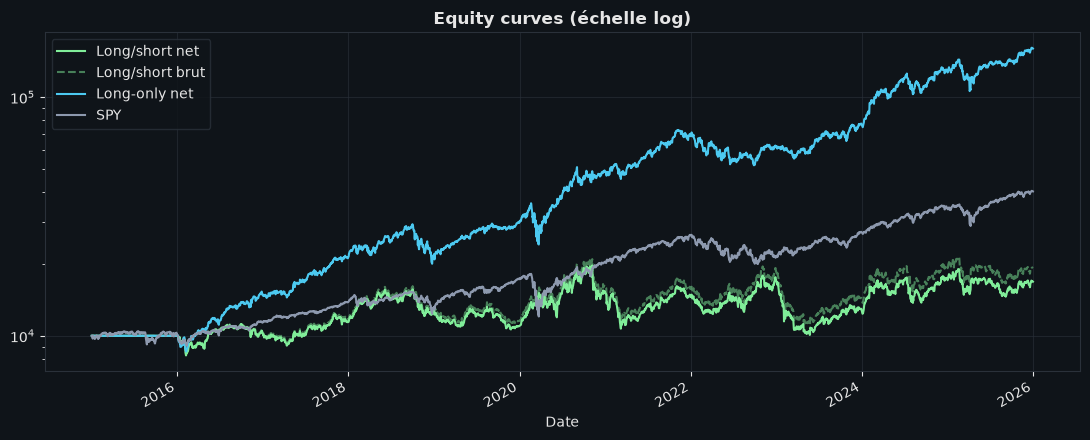

In [4]:
score = factors["momentum 12-1"]
w_ls = quantile_weights(score, 0.2, 0.2, rebalance_every=21)
w_lo = quantile_weights(score, 0.2, 0.2, long_only=True, rebalance_every=21)

bt = PortfolioBacktester(rets, borrow_bps=BORROW_BPS)
ls, lo = bt.run(w_ls, market_returns=spy_r), bt.run(w_lo, market_returns=spy_r)
ls_gross = bt.run(w_ls, costs=False)
display(pd.DataFrame({"L/S net": ls["metrics"], "L/S brut": ls_gross["metrics"], "Long-only": lo["metrics"]}))
print("Expositions/coûts L/S :", ls["exposure"])
print("CAPM L/S       :", ls["capm"]); print("CAPM Long-only :", lo["capm"])

spy_eq = 10_000 * (1 + spy_r.fillna(0)).cumprod()
fig, ax = plt.subplots()
ls["results"]["equity_curve"].plot(ax=ax, color=GREEN, label="Long/short net")
ls["results"]["equity_gross"].plot(ax=ax, color=GREEN, ls="--", alpha=.5, label="Long/short brut")
lo["results"]["equity_curve"].plot(ax=ax, color=BLUE, label="Long-only net")
spy_eq.plot(ax=ax, color=GREY, label="SPY"); ax.set_yscale("log")
ax.set_title("Equity curves (échelle log)"); ax.legend(); save("equity"); plt.show()

## 3. Expositions brute et nette

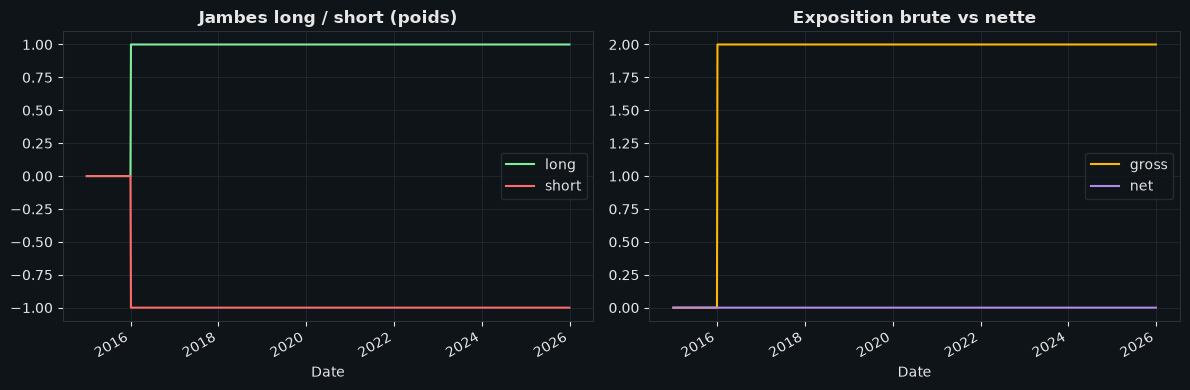

In [5]:
exp = exposure_summary(w_ls)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
exp[["long","short"]].plot(ax=axs[0], color=[GREEN, RED]); axs[0].set_title("Jambes long / short (poids)")
exp[["gross","net"]].plot(ax=axs[1], color=[ORANGE, PURPLE]); axs[1].set_title("Exposition brute vs nette")
save("exposure"); plt.show()

## 4. Beta glissant et couverture
**Dollar-neutral ≠ beta-neutral** : `net = 0` n'annule le marché que si les deux jambes ont le même beta moyen.

Beta vs SPY (régression) avant couverture : 0.214
Beta vs SPY (régression) après couverture : -0.038
⚠ couverture simulée SANS coûts (le short SPY coûterait aussi frais et slippage)


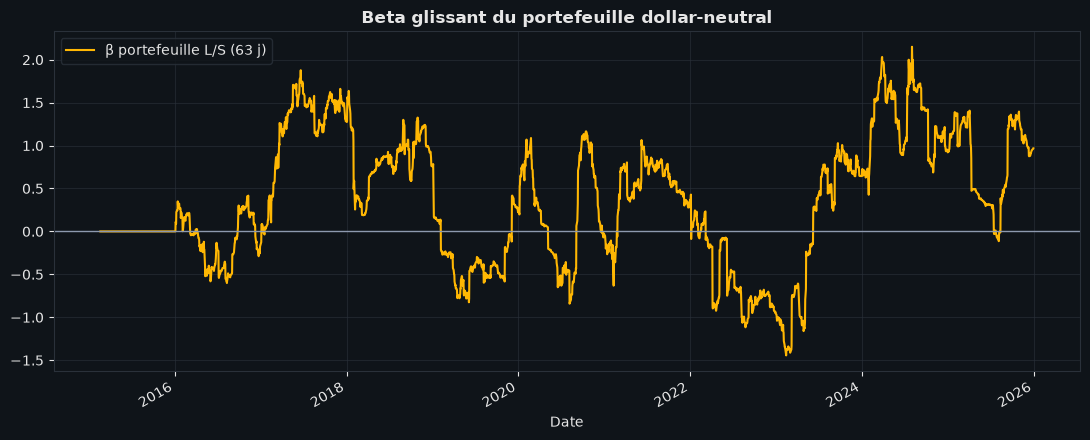

In [6]:
betas = rolling_beta(rets, spy_r, window=63)
pb = portfolio_beta(w_ls.shift(1), betas.shift(1))      # beta DÉTENU pendant t (décidé en t-1)
pr = portfolio_returns(w_ls, rets)
hr = hedged_returns(pr, beta_hedge(w_ls, betas), spy_r)

print("Beta vs SPY (régression) avant couverture :", fama_french_alpha(pr, spy_r)["beta"])
print("Beta vs SPY (régression) après couverture :", fama_french_alpha(hr, spy_r)["beta"])
print("⚠ couverture simulée SANS coûts (le short SPY coûterait aussi frais et slippage)")

fig, ax = plt.subplots()
pb.plot(ax=ax, color=ORANGE, label="β portefeuille L/S (63 j)"); ax.axhline(0, color=GREY, lw=1)
ax.set_title("Beta glissant du portefeuille dollar-neutral"); ax.legend(); save("beta"); plt.show()

## 5. Le short coûte : sensibilité au frais d'emprunt

In [7]:
rows = {}
for b in [0, 30, 100, 300, 1000]:
    m = PortfolioBacktester(rets, borrow_bps=b).run(w_ls)["metrics"]
    rows[f"{b} bps/an"] = {k: m[k] for k in ["CAGR (%)", "Sharpe", "Max Drawdown (%)", "Capital final (€)"]}
display(pd.DataFrame(rows).T)

,CAGR (%),Sharpe,Max Drawdown (%),Capital final (€)
0 bps/an,5.16,0.33,-48.49,17365.16
30 bps/an,4.87,0.32,-48.88,16853.58
100 bps/an,4.21,0.29,-49.78,15717.72
300 bps/an,2.33,0.22,-52.26,12876.75
1000 bps/an,-3.98,-0.03,-60.06,6407.81


## 6. Corrélation ≠ cointégration
Deux actifs très corrélés (en rendements) peuvent diverger indéfiniment. Seul le test d'Engle-Granger
(sur les **log-prix**) dit si l'écart revient. Attention au *data snooping* : plus on teste de paires,
plus des « paires cointégrées » apparaissent par hasard (Bonferroni : seuil = 0,05 / nb de paires).

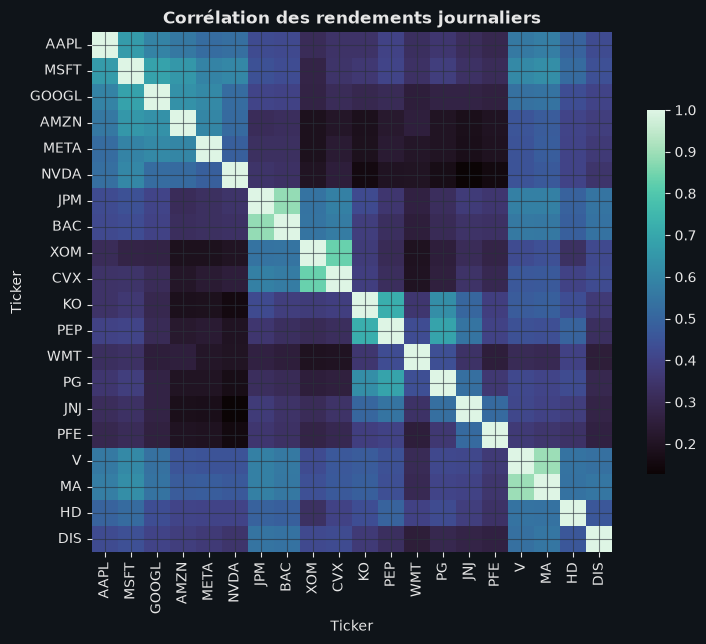

In [8]:
import seaborn as sns
corr = rets.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, cmap="mako", ax=ax, square=True, cbar_kws={"shrink": .7},
            xticklabels=True, yticklabels=True)
ax.set_title("Corrélation des rendements journaliers"); save("corr"); plt.show()

## 7. Pair trading

In [9]:
if SYNTHETIC:
    from backtester.synthetic import make_pair
    py, px = make_pair(); CANDIDATES = {("Y", "X"): (py, px)}
else:
    CANDIDATES = {p: (close[p[0]], close[p[1]]) for p in [("KO","PEP"),("XOM","CVX"),("V","MA")]
                  if p[0] in close and p[1] in close}

rows = {}
for (a, b), (cy, cx) in CANDIDATES.items():
    r = cointegration_test(np.log(cy), np.log(cx))
    r["corr rendements"] = round(cy.pct_change().corr(cx.pct_change()), 2)
    rows[f"{a}/{b}"] = r
coint_table = pd.DataFrame(rows).T
display(coint_table)
print(f"Seuil Bonferroni ({len(rows)} paires) : {0.05/len(rows):.3f}")

,t_stat,pvalue,crit_5pct,cointegrated,half_life,beta,n,corr rendements
KO/PEP,-1.534,0.748,-3.338,False,288.5,0.868,2765,0.72
XOM/CVX,-1.497,0.7624,-3.338,False,389.2,0.9633,2765,0.83
V/MA,-3.834,0.0122,-3.338,True,45.8,0.8375,2765,0.9


Seuil Bonferroni (3 paires) : 0.017


Paire étudiée : ('V', 'MA') | cointégrée : True
{'CAGR (%)': 0.65, 'Sharpe': np.float64(0.17), 'Max Drawdown (%)': -13.23, 'Nb trades': 50}


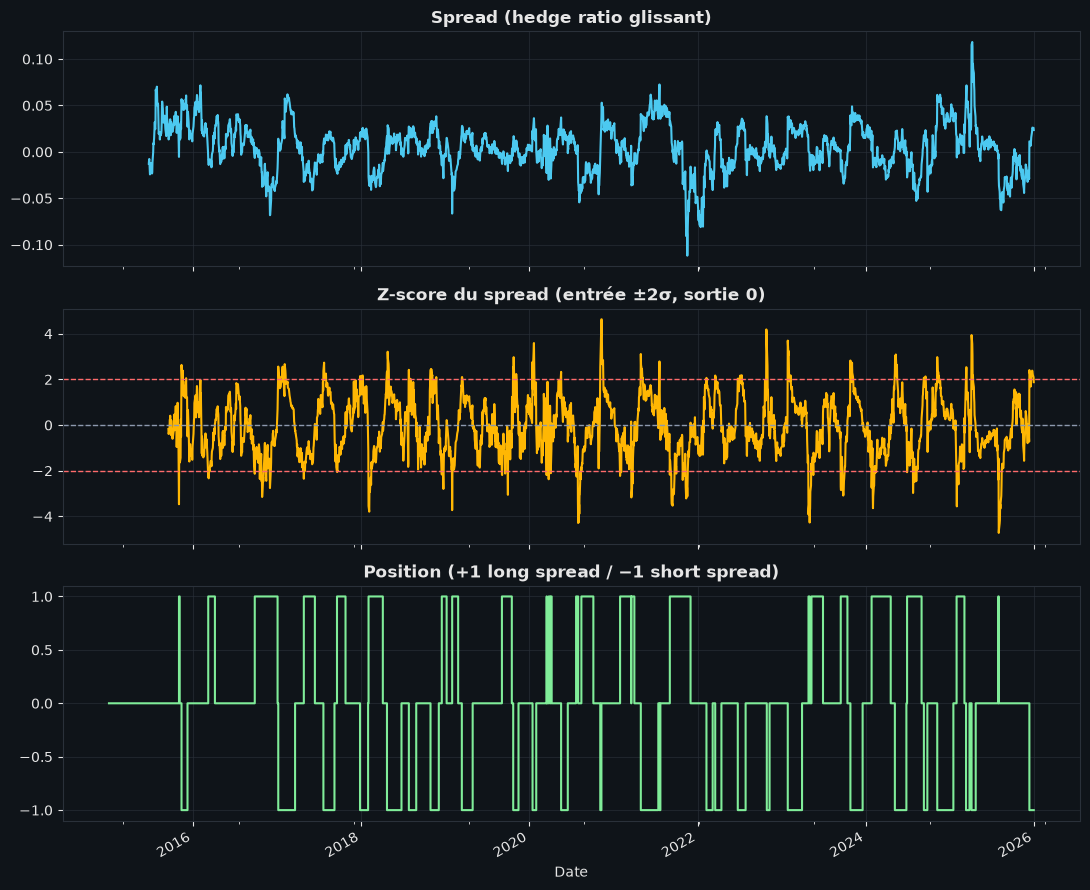

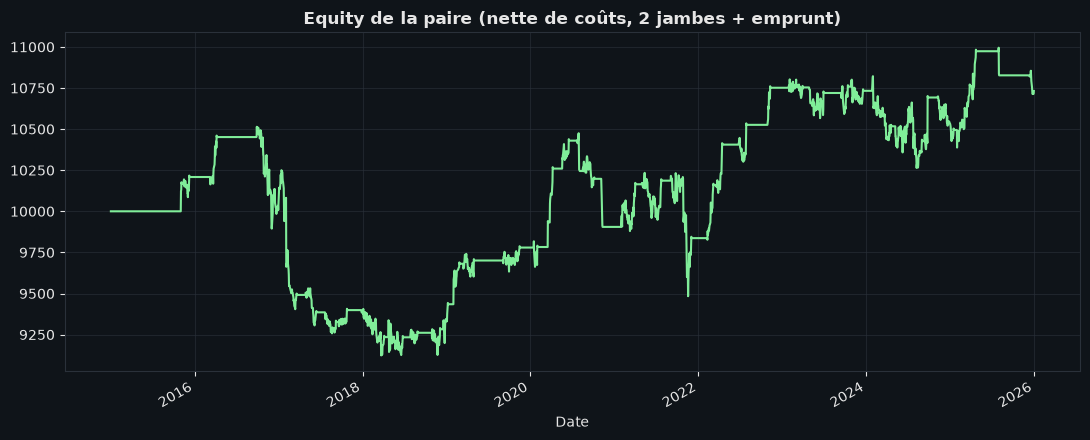

In [10]:
pair = next((k for k in CANDIDATES if coint_table.loc[f"{k[0]}/{k[1]}", "cointegrated"]), list(CANDIDATES)[0])
cy, cx = CANDIDATES[pair]; ly, lx = np.log(cy), np.log(cx)
print("Paire étudiée :", pair, "| cointégrée :", bool(coint_table.loc[f"{pair[0]}/{pair[1]}", "cointegrated"]))

sig = pairs_signal(ly, lx, hedge_window=120, z_window=60, entry_z=2.0, exit_z=0.0, stop_z=4.0)
prs = pair_returns(cy, cx, sig["position"], sig["beta"], borrow_bps=BORROW_BPS)
eq = 10_000 * (1 + prs["strategy_returns"]).cumprod()
print({k: v for k, v in full_metrics(prs["strategy_returns"], eq, sig["position"]).items()
       if k in ["CAGR (%)", "Sharpe", "Max Drawdown (%)", "Nb trades"]})

fig, axs = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
sig["spread"].plot(ax=axs[0], color=BLUE); axs[0].set_title("Spread (hedge ratio glissant)")
sig["z"].plot(ax=axs[1], color=ORANGE)
for lvl, c in [(2, RED), (-2, RED), (0, GREY)]: axs[1].axhline(lvl, color=c, lw=1, ls="--")
axs[1].set_title("Z-score du spread (entrée ±2σ, sortie 0)")
(sig["position"]).plot(ax=axs[2], color=GREEN, drawstyle="steps-post"); axs[2].set_title("Position (+1 long spread / −1 short spread)")
save("pair"); plt.show()

fig, ax = plt.subplots(); eq.plot(ax=ax, color=GREEN); ax.set_title("Equity de la paire (nette de coûts, 2 jambes + emprunt)")
save("pair_equity"); plt.show()

## 8. Stabilité et limites

In [11]:
by_year = ls["results"]["strategy_returns"].groupby(ls["results"].index.year).apply(
    lambda r: pd.Series({"Rendement (%)": ((1 + r).prod() - 1) * 100,
                         "Sharpe": r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else 0}))
display(by_year.unstack().round(2))

,Rendement (%),Sharpe
Date,,
2015,0.00,0.00
2016,2.80,0.24
2017,10.90,0.66
2018,11.89,0.59
2019,-13.99,-0.81
2020,38.25,0.98
2021,-4.11,-0.05
2022,17.64,0.72
2023,-24.32,-0.88


**À retenir**
- Long/short ≠ sans risque : regarder drawdown **et** beta résiduel, pas seulement le Sharpe.
- Net de coûts d'emprunt, deux jambes, turnover : le Sharpe brut est une borne haute.
- Biais de survie (univers actuel) : les résultats sur tickers réels sont probablement optimistes.
- Cointégration : à tester, jamais à supposer ; peut se casser (stop de cointégration dans `pairs_signal`).
- Non fait ici : `walk_forward`/`purged_cv` appliqués au portefeuille (ces fonctions ciblent un seul actif) → séance suivante.